# Real names → candidate identities → graph ranking
Run one cell at a time with **Shift+Enter**. Every step displays its output. No model calls, training, or manual decisions are required.

This is a small **AGDISTIS-inspired demonstration**, not the full AGDISTIS implementation or a validated production linker. It uses real, unchanged rows from Daniel's 17 October 2026 upload and a saved part of our unified source graph.

For this exercise, match **PER mentions to people only**. Other types, unknown-entity policy, relation extraction, event extraction, and final graph export remain outside this exercise. A failed match does **not** prove that a person is unknown.

**Route:** raw paragraph → page candidates → name similarity → real graph links → HITS ranking → automatic suggestion or unresolved.

### 0. Load the saved real data
Keep `real_examples.json` beside this notebook. The normal run is offline. Requires Python, pandas, NetworkX, and matplotlib. These are already available in the local Anaconda environment.

The snapshot contains eight paragraphs from two pages. `prepare_examples.py` can rebuild it from the pinned parquet and the existing local graph inputs. It checks the upload's Git blob and records input SHA-256 hashes.

In [1]:
import json
import re
import unicodedata
from pathlib import Path

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HERE = Path.cwd()
if not (HERE / "real_examples.json").exists():
    HERE = HERE / "GG_Data/entity_resolution"  # Also works from the repository root.
bundle = json.loads((HERE / "real_examples.json").read_text(encoding="utf-8"))
raw = pd.DataFrame(bundle["mentions"])
entities = bundle["entities"]
all_edges = pd.DataFrame(bundle["edges"])
label = lambda q: entities.get(q, {}).get("label", q)
assert all(r.Text[r.start:r.end] == r.word for r in raw.itertuples())
display(raw.groupby(["Source", "Index"]).agg(raw_rows=("word", "size")).reset_index())
print("Mapping:", bundle["provenance"]["mapping_version"])
print("Daniel commit:", bundle["provenance"]["daniel_commit"])

,Source,Index,raw_rows
0,14th Indian Infantry Division,1,8
1,14th Indian Infantry Division,6,7
2,14th Indian Infantry Division,34,19
3,Attack on Pearl Harbor,1,38
4,Attack on Pearl Harbor,2,13
5,Attack on Pearl Harbor,3,28
6,Attack on Pearl Harbor,8,15
7,Attack on Pearl Harbor,11,12


Mapping: relation-map-v2.1.0
Daniel commit: 43e35453421b032fc67d426d7d16fe436574b0fa


### 1. Choose a real paragraph
Change `SOURCE` and `PARAGRAPH`, then run the cells below again. Examples:

| Source | Paragraph | What you can inspect |
|---|---:|---|
| 14th Indian Infantry Division | 1 | Full name and overlapping spans |
| 14th Indian Infantry Division | 6 | Irwin and Lloyd, including titles |
| 14th Indian Infantry Division | 34 | Names that the page candidate pool can miss |
| Attack on Pearl Harbor | 1, 2, 3 | Yamamoto, Nagumo, Roosevelt |
| Attack on Pearl Harbor | 8, 11 | Short names: Allison and Roosevelt |

Controls are examples for exploration, **not calibrated settings**. A name score or HITS score is not a match probability.

In [2]:
SOURCE = "Attack on Pearl Harbor"
PARAGRAPH = 1
MIN_NAME_SIM = 0.35    # Keep a candidate if its best label/alias passes this.
GRAPH_DEPTH = 1       # Saved graph supports 0 or 1 outgoing expansion steps.
HITS_STEPS = 20
MIN_ACCEPT_NAME = 0.80
MIN_AUTHORITY_GAP = 0.20  # (winner - runner-up) / winner, for multiple candidates.

assert SOURCE in bundle["pages"]
assert 0 <= GRAPH_DEPTH <= bundle["provenance"]["max_graph_depth"]
assert 0 <= MIN_NAME_SIM <= 1 and 0 <= MIN_ACCEPT_NAME <= 1
assert 0 <= MIN_AUTHORITY_GAP <= 1 and HITS_STEPS >= 1
paragraph = raw[(raw.Source == SOURCE) & (raw.Index == PARAGRAPH)].copy()
if paragraph.empty:
    raise ValueError("Choose a Source/Index pair from step 0.")
assert paragraph.Text.nunique() == 1
display(Markdown(paragraph.iloc[0].Text))
display(paragraph[["entity_group", "word", "start", "end", "score", "subtype"]])

The attack on Pearl Harbor was preceded by months of negotiations between the US and Japan over the future of the Pacific. Japanese demands included that the US end its sanctions against Japan, cease aiding China in the Second Sino-Japanese War, and allow Japan access to the resources of the Dutch East Indies. Japan dispatched its naval attack group on November 26, 1941, just before receiving the Hull note, which stated the US desire that Japan withdraw from China and French Indochina. Isoroku Yamamoto, commander of the Japanese Combined Fleet, planned the attack as a pre-emptive strike on the Pacific Fleet, which had been based at Pearl Harbor since 1940 in order to prevent it from interfering with Japan's planned actions in Southeast Asia. Yamamoto hoped that the strike would enable Japan to make rapid territorial gains and negotiate peace. In addition to Pearl Harbor, over seven hours Japan launched coordinated attacks on the US-held Philippines, Guam, and Wake Island, as well as on the British Empire in Malaya, Singapore, and Hong Kong.

,entity_group,word,start,end,score,subtype
34,LOC,Pearl Harbor,14,26,0.999583,LOC
35,LOC,US,78,80,0.997861,LOC
36,LOC,Japan,85,90,0.999747,LOC
37,LOC,Pacific,114,121,0.999211,LOC
38,MISC,Japanese,123,131,0.999745,MISC
39,LOC,US,158,160,0.989774,LOC
40,LOC,Japan,187,192,0.999759,LOC
41,LOC,China,207,212,0.999796,LOC
42,MISC,Second Sino-Japanese War,220,244,0.994727,MISC
43,LOC,Japan,256,261,0.999766,LOC


### 2. Narrow to known people connected to this page
Resolve the page title to its saved Wikidata ID. Take its direct incoming or outgoing neighbours in the unified source assertions. Keep those explicitly typed as human (`Q5`) in the saved Wikidata data.

This is a strict page filter. It can miss a real person. A page connection only makes a candidate eligible; it does not prove the mention's identity. Type hierarchy rules are intentionally outside this exercise.

In [3]:
page_qid = bundle["pages"][SOURCE]
pool_ids = [q for q in bundle["page_pools"][SOURCE] if entities[q]["is_person"]]
pool = pd.DataFrame([{"qid": q, "label": label(q), "aliases": entities[q]["aliases"],
                      "description": entities[q]["description"]} for q in pool_ids])
mentions = paragraph[paragraph.entity_group == "PER"].copy().reset_index(drop=True)
mentions["mention_id"] = [f"{SOURCE}|{PARAGRAPH}|{r.start}|{r.end}|PER" for r in mentions.itertuples()]
print("Page:", page_qid, "| known people:", len(pool), "| person spans:", len(mentions))
display(pool)

Page: Q52418 | known people: 96 | person spans: 1


,qid,label,aliases,description
0,Q103292736,John P. Coursey,[John Paul Coursey],American Brigadier general
1,Q11523508,Shigeharu Murata,[],Japanese World War II pilot
2,Q116351,Mitsuo Fuchida,[],Japanese Naval officer (1902-1976)
3,Q11671646,Kakuichi Takahashi,[Takahashi Kakuichi],Japanese naval aviator
4,Q118499653,Melvin Storer,"[Melvin T Storer, Melvin Tyler Storer]",American shipfitter
...,...,...,...,...
91,Q96364376,,"[Willard Augustus Kitts III, Willard Augustus ...",United States navy officer
92,Q96378481,Frederick Martin,[Frederick Leroy Martin],commander of US Army Air Forces (1882-1954)
93,Q97016257,Armond H. DeLalio,[Armond Hector DeLalio],USMC Navy Cross recipient
94,Q98060424,William W. Smith,[William Ward Smith],American Vice admiral


### 3. Compare names with character trigrams
Keep letters and numbers, ignore case and accents, and compare sets of three adjacent characters. This demo uses Dice similarity: `2 × shared trigrams / total trigrams`.

For each candidate, use its best English label or alias from the source snapshot. Titles are not removed by a hidden rule. The table shows exactly which alias won. Daniel's extraction score is preserved but is **not** used as identity confidence.

In [4]:
import sys
sys.path.insert(0, str(HERE))
from generate_candidates import normalize, trigrams, similarity

rows = []
for mention in mentions.itertuples():
    for qid in pool_ids:
        names = sorted(set([label(qid)] + entities[qid]["aliases"]))
        best_alias = max(names, key=lambda name: similarity(mention.word, name))
        rows.append({"mention_id": mention.mention_id, "word": mention.word, "qid": qid,
                     "label": label(qid), "best_alias": best_alias,
                     "name_similarity": similarity(mention.word, best_alias)})
name_scores = pd.DataFrame(rows, columns=["mention_id", "word", "qid", "label", "best_alias", "name_similarity"])
candidates = (name_scores[name_scores.name_similarity >= MIN_NAME_SIM]
              .sort_values(["mention_id", "name_similarity", "qid"], ascending=[True, False, True])
              .copy())
display(candidates[["word", "qid", "label", "best_alias", "name_similarity"]])
# Inspect the actual character pieces for the first retained candidate.
if not candidates.empty:
    example = candidates.iloc[0]
    display(pd.DataFrame({"shared trigrams": sorted(trigrams(example.word) & trigrams(example.best_alias))}))
print("All comparisons are in name_scores; retained comparisons are in candidates.")

,word,qid,label,best_alias,name_similarity
12,Isoroku Yamamoto,Q152325,Isoroku Yamamoto,Isoroku Yamamoto,1.000000
51,Isoroku Yamamoto,Q5986314,Ichirō Yamamoto,Ichirou Yamamoto,0.571429


,shared trigrams
0,ya
1,ama
2,amo
3,iso
4,ku
5,mam
6,mot
7,oku
8,oro
9,oto


All comparisons are in name_scores; retained comparisons are in candidates.


### 4. Build the context graph from real assertions
Start with all retained candidates **plus the page node**. Expand through outgoing links for the chosen depth, then retain links between the reached nodes. Ranking keeps source direction. Multiple assertions for one directed pair count as one HITS link.

The saved edges replay relation-map-v2.1.0 over the legacy assertion export: restore original endpoints first, apply approved record exclusions, then apply the new mapping direction. No synthetic reverse links are added. Source predicates and record IDs remain visible.

The page anchor is a demo addition. Common links, missing data, and graph direction can change the ranking. No paragraph semantics or language model is used here.

In [5]:
known_graph = nx.DiGraph()
known_graph.add_edges_from(zip(all_edges.subject, all_edges.object))
seeds = set(candidates.qid) | {page_qid}
reached = set(seeds)
for _ in range(GRAPH_DEPTH):
    reached |= {target for q in list(reached) for target in known_graph.successors(q)}
graph = known_graph.subgraph(reached).copy()
graph.add_nodes_from(seeds)
evidence = all_edges[all_edges.subject.isin(reached) & all_edges.object.isin(reached)].copy()
print("Nodes:", len(graph), "| directed pairs:", graph.number_of_edges(), "| source assertions:", len(evidence))
page_evidence = evidence[(evidence.subject == page_qid) | (evidence.object == page_qid)].copy()
page_evidence["subject_label"] = page_evidence.subject.map(label)
page_evidence["object_label"] = page_evidence.object.map(label)
display(page_evidence[["subject_label", "relation", "object_label", "source", "source_predicate", "source_record_id"]])

Nodes: 84 | directed pairs: 269 | source assertions: 368


,subject_label,relation,object_label,source,source_predicate,source_record_id
105,Pearl Harbor,wd:P793,Attack on Pearl Harbor,Wikidata,wd:P793,Q127091$d2fffc5a-4aaf-7a5d-8cd1-9acf3dbba51e
268,Isoroku Yamamoto,wd:P607,Attack on Pearl Harbor,Wikidata,wd:P607,Q152325$7664f9df-4870-153d-4b86-421d73e15e7b
341,Pacific War,wd:P793,Attack on Pearl Harbor,Wikidata,wd:P793,Q184425$550ae209-467b-1d8a-fca4-ec33d6e3f88d
554,Chūichi Nagumo,wd:P607,Attack on Pearl Harbor,Wikidata,wd:P607,Q295839$4a49a669-415c-a427-79ad-daa0bf703304
704,Attack on Pearl Harbor,wd:P361,World War II,Wikidata,wd:P527,Q362$f17814a6-481b-e410-93a0-f1b14d67a8ce
822,Battleship Row,wd:P361,Attack on Pearl Harbor,Wikidata,wd:P361,Q4873243$af372bbd-47c3-e7fb-197a-a20130210fb5
908,Attack on Pearl Harbor,wd:P276,Pearl Harbor,Wikidata,wd:P276,Q52418$c9943ae8-4f72-601a-ab2a-227ce85fdc4e
909,Attack on Pearl Harbor,wd:P31,Q6982012,Wikidata,wd:P31,q52418$0cd7b128-4df0-47a3-4a61-9d777f2f387a
910,Attack on Pearl Harbor,wd:P31,Q178561,Wikidata,wd:P31,Q52418$d667e3aa-46b6-c532-c21f-b6b51697e49a
911,Attack on Pearl Harbor,wd:P31,Q4698343,Wikidata,wd:P31,Q52418$d313a141-4e53-df9c-eb16-7869a3e60b7b


### 5. See the graph
For a readable view, show the page and candidate nodes only. The full graph used in ranking is still `graph`. Arrows show the saved direction; layout position has no meaning.

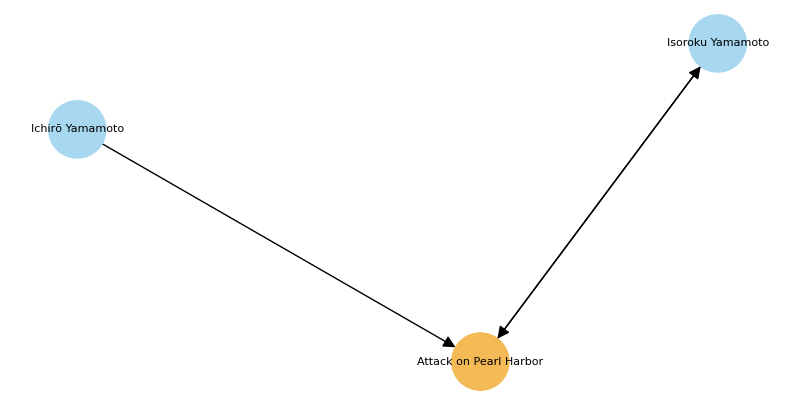

In [6]:
view = graph.subgraph(seeds)
plt.figure(figsize=(10, 5))
pos = nx.spring_layout(view, seed=42)
nx.draw_networkx(view, pos, labels={q: label(q) for q in view},
                 node_color=["#f4ba55" if q == page_qid else "#a7d8ef" for q in view],
                 node_size=1700, font_size=8, arrows=True, arrowsize=18)
plt.axis("off")
plt.show()

### 6. Run HITS and inspect its iterations
A node's **authority** receives weight from nodes that point to it. A node's **hub** receives weight from nodes it points to. Repeat these updates and normalize after each update.

Here the updates are written out so you can inspect them. All nodes start equally. This is unsupervised: no correct-match labels are supplied. Authority measures graph structure, not truth. An isolated candidate can have zero authority.

In [7]:
def hits_steps(g: nx.DiGraph, steps: int) -> pd.DataFrame:
    hubs = dict.fromkeys(g, 1 / max(len(g), 1))
    history = []
    for step in range(1, steps + 1):
        authority = {q: sum(hubs[p] for p in g.predecessors(q)) for q in g}
        scale = sum(authority.values()) or 1.0
        authority = {q: score / scale for q, score in authority.items()}
        hubs = {q: sum(authority[t] for t in g.successors(q)) for q in g}
        scale = sum(hubs.values()) or 1.0
        hubs = {q: score / scale for q, score in hubs.items()}
        history.extend({"iteration": step, "qid": q, "authority": authority[q], "hub": hubs[q]} for q in g)
    return pd.DataFrame(history, columns=["iteration", "qid", "authority", "hub"])

history = hits_steps(graph, HITS_STEPS)
authority = history[history.iteration == HITS_STEPS].set_index("qid").authority
ranked = candidates.assign(authority=candidates.qid.map(authority).fillna(0))
ranked = ranked.sort_values(["mention_id", "authority", "name_similarity", "qid"], ascending=[True, False, False, True])
display(ranked[["word", "label", "best_alias", "name_similarity", "authority"]])
display(history[history.qid.isin(candidates.qid)].pivot(index="iteration", columns="qid", values="authority"))

,word,label,best_alias,name_similarity,authority
12,Isoroku Yamamoto,Isoroku Yamamoto,Isoroku Yamamoto,1.000000,0.012688
51,Isoroku Yamamoto,Ichirō Yamamoto,Ichirou Yamamoto,0.571429,0.000000


qid,Q152325,Q5986314
iteration,,
1,0.033457,0.0
2,0.018199,0.0
3,0.014712,0.0
4,0.013504,0.0
5,0.013027,0.0
6,0.012830,0.0
7,0.012748,0.0
8,0.012713,0.0
9,0.012698,0.0


### 7. Make an automatic decision with an explicit rule
This demo adds an **unvalidated acceptance rule** to the graph ranking:

- No candidate: unresolved within this page pool.
- One candidate: suggest it only if name similarity passes `MIN_ACCEPT_NAME`.
- Several candidates: suggest the highest-authority candidate only if its name passes that threshold and its relative authority gap passes `MIN_AUTHORITY_GAP`.

A zero authority or tied authority cannot win the multi-candidate rule. A single-candidate suggestion comes from the name and page filter; it is not evidence that HITS helped. “Suggested” is not verified gold truth. No new entity is created.

In [8]:
def decide(options: pd.DataFrame, min_name: float, min_gap: float) -> dict:
    if options.empty:
        return {"suggested_qid": None, "decision": "UNRESOLVED", "reason": "no candidate in page pool", "authority_gap": None}
    options = options.sort_values(["authority", "name_similarity", "qid"], ascending=[False, False, True])
    best = options.iloc[0]
    gap = None if len(options) == 1 else ((best.authority - options.iloc[1].authority) / best.authority if best.authority > 0 else 0.0)
    accepted = best.name_similarity >= min_name and (len(options) == 1 or (gap > 0 and gap >= min_gap))
    reason = "single candidate; name rule passed" if len(options) == 1 else "graph winner; name and gap rules passed"
    return {"suggested_qid": best.qid if accepted else None,
            "decision": "SUGGESTED" if accepted else "UNRESOLVED",
            "reason": reason if accepted else "name score or graph separation too weak",
            "authority_gap": gap}

results = []
for m in mentions.itertuples():
    result = decide(ranked[ranked.mention_id == m.mention_id], MIN_ACCEPT_NAME, MIN_AUTHORITY_GAP)
    results.append({"mention_id": m.mention_id, "word": m.word, "start": m.start, "end": m.end,
                    "extraction_score": m.score, **result})
results = pd.DataFrame(results)
if not results.empty:
    results["suggested_label"] = results.suggested_qid.map(lambda q: label(q) if q else None)
display(results)

,mention_id,word,start,end,extraction_score,suggested_qid,decision,reason,authority_gap,suggested_label
0,Attack on Pearl Harbor|1|491|507|PER,Isoroku Yamamoto,491,507,0.998083,Q152325,SUGGESTED,graph winner; name and gap rules passed,1.0,Isoroku Yamamoto


### 8. Small checks and experiments
These checks verify span integrity, score behaviour, directed HITS updates, and rejection of ties. They do not measure linking accuracy.

Try changing only one control at a time: raise the name threshold, change graph depth from 1 to 0, or select paragraph 34. Compare `name_scores`, `evidence`, `history`, and `results`. Rerun from step 1 after a change.

Overlapping mentions remain separate. Full AGDISTIS also has label expansion and other normalization rules that this short demo omits. The snapshot is deliberately small and page scope can hide correct candidates. We must test candidate recall and linking accuracy on a separate evaluation set before adopting a production method.

In [9]:
assert all(r.Text[r.start:r.end] == r.word for r in raw.itertuples())
assert similarity("Noel Irwin", "Noel Irwin") == 1
assert similarity("", "Noel Irwin") == 0
assert similarity("NOEL  IRWIN", "Noel Irwin") == 1
check = hits_steps(nx.DiGraph([("page", "person")]), 2)
last = check[check.iteration == 2].set_index("qid")
assert last.loc["person", "authority"] == 1 and last.loc["page", "authority"] == 0
assert last.loc["page", "hub"] == 1
assert decide(ranked.iloc[:0], 0.8, 0.2)["suggested_qid"] is None
tied = pd.DataFrame([{"qid": "a", "authority": 0.5, "name_similarity": 1.0},
                     {"qid": "b", "authority": 0.5, "name_similarity": 1.0}])
assert decide(tied, 0.8, 0.0)["suggested_qid"] is None
assert not candidates.duplicated(["mention_id", "qid"]).any()
assert candidates.name_similarity.between(0, 1).all()
assert not history[["authority", "hub"]].isna().any().any()
print("Checks passed. These are software checks, not an accuracy claim.")

Checks passed. These are software checks, not an accuracy claim.


### Sources and reproducibility
- [Daniel's pinned upload](https://github.com/EtzionR/Corpus2GeoRAG_Pacific/blob/43e35453421b032fc67d426d7d16fe436574b0fa/Data/georag_selected_v2_full_n36335_r482092353_20261016.parquet)
- [AGDISTIS paper](https://svn.aksw.org/papers/2014/ISWC_AGDISTIS/public.pdf), especially Algorithms 1 and 2.
- [Official AGDISTIS code](https://github.com/dice-group/AGDISTIS).
- Mapping source: `GG_Data/mapping/RELATION_MAPPING_TABLE_v2.1.0.csv`.
- Every example edge retains source predicate, source record ID, and observation ID. English names and aliases retain the saved Wikidata revision. Input hashes are available in `bundle["provenance"]`.

The teaching changes are: strict one-hop page/person candidate scope, simple Unicode normalization and Dice trigrams, no label expansion, a page anchor, depth capped at 1, and a custom abstention rule. HITS uses unweighted directed pairs. The full source evidence remains available through its identifiers.